# Tarification automobile : analyse pas à pas

Ce notebook reprend le pipeline de `main.py` étape par étape, avec les résultats affichés :
données freMTPL2, GLM de fréquence et de coût, GLM avec interactions, XGBoost, puis comparaison sur un jeu de test.

Pour le relancer : `pip install -r requirements.txt`, puis exécuter les cellules (environ 3 minutes ; les données sont téléchargées depuis OpenML au premier lancement).

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # accès au dossier src/

import numpy as np
import pandas as pd
import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
from IPython.display import Image, display

from src.data import build_dataset, train_test_split_policies
from src.features import add_features
from src import models, evaluation, plots

pd.set_option("display.float_format", "{:,.4f}".format)
FIG = Path("../outputs/figures")

## 1. Les données

Une ligne par contrat : exposition (fraction d'année), nombre de sinistres, charge sinistre et variables tarifaires.

In [2]:
df = add_features(build_dataset())
train, test = train_test_split_policies(df)
print(f"{len(df):,} contrats | train {len(train):,} | test {len(test):,}".replace(",", " "))
df[["Exposure", "ClaimNb", "ClaimAmount", "DrivAge", "BonusMalus", "VehAge", "VehPower", "Area", "VehGas", "Region"]].head()

678 013 contrats | train 541 875 | test 136 138


,Exposure,ClaimNb,ClaimAmount,DrivAge,BonusMalus,VehAge,VehPower,Area,VehGas,Region
0,0.1000,0,0.0000,55,50,0,5,D,Regular,R82
1,0.7700,0,0.0000,55,50,0,5,D,Regular,R82
2,0.7500,0,0.0000,52,50,2,6,B,Diesel,R22
3,0.0900,0,0.0000,46,50,0,7,B,Diesel,R72
4,0.8400,0,0.0000,46,50,0,7,B,Diesel,R72


In [3]:
resume = pd.Series({
    "Exposition totale (années)": df["Exposure"].sum(),
    "Nombre de sinistres": df["ClaimNb"].sum(),
    "Fréquence annuelle": df["ClaimNb"].sum() / df["Exposure"].sum(),
    "Coût moyen d'un sinistre (€)": df["ClaimAmount"].sum() / df["ClaimNb"].sum(),
    "Prime pure moyenne (€ / an)": df["ClaimAmount"].sum() / df["Exposure"].sum(),
})
resume.to_frame("valeur")

,valeur
Exposition totale (années),"358,360.1055"
Nombre de sinistres,"26,405.0000"
Fréquence annuelle,0.0737
Coût moyen d'un sinistre (€),"1,976.9145"
Prime pure moyenne (€ / an),145.6647


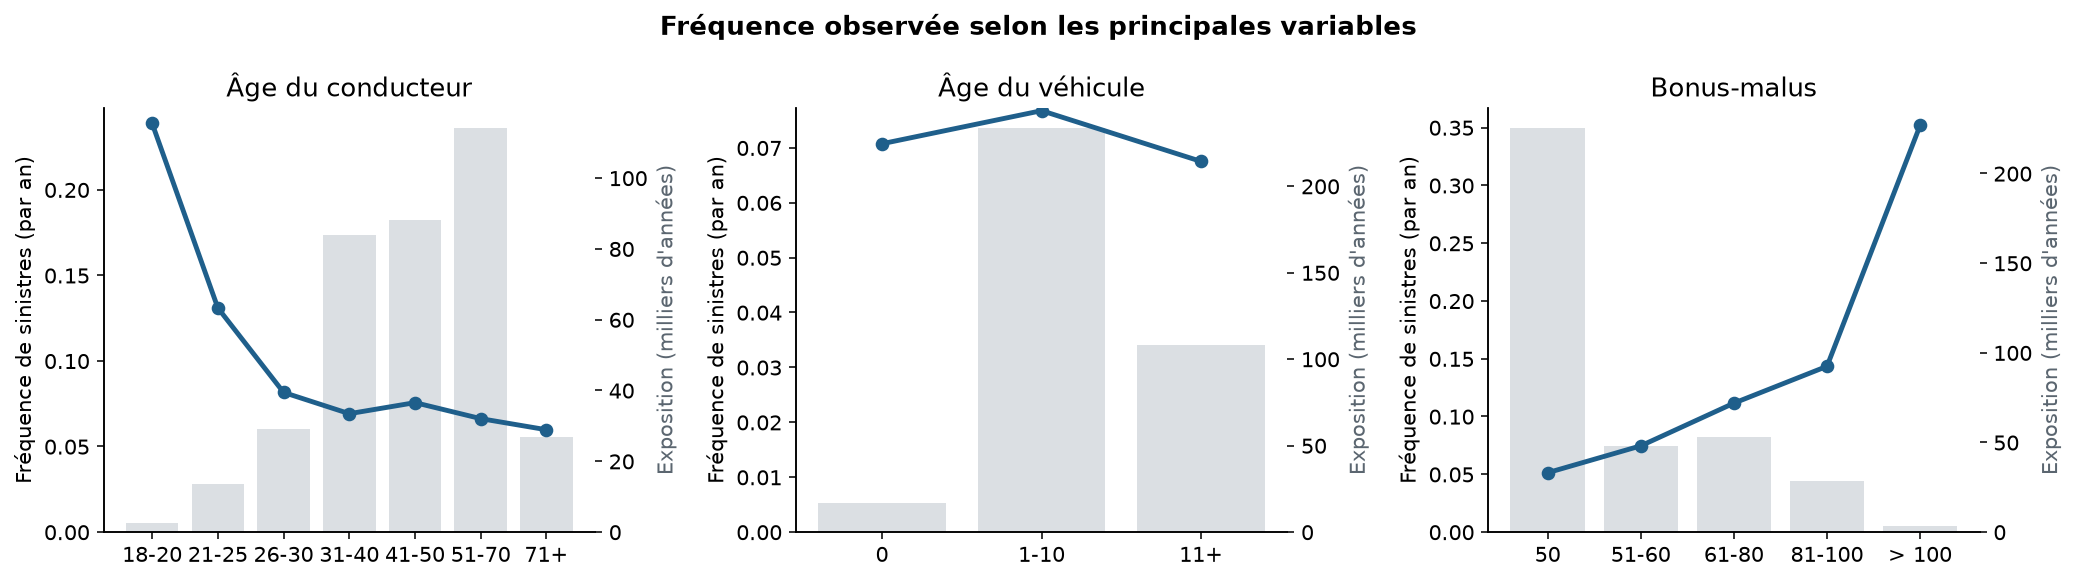

In [4]:
plots.frequency_by_variable(df, FIG / "frequence_par_variable.png")
display(Image(FIG / "frequence_par_variable.png"))

## 2. GLM de fréquence (Poisson) et de coût moyen (Gamma)

Offset log(exposition) pour la fréquence ; le coût moyen est modélisé sur les contrats sinistrés, pondéré par le nombre de sinistres.

In [5]:
glm_f = models.fit_glm_frequency(train)
glm_fi = models.fit_glm_frequency(train, interactions=True)
glm_s = models.fit_glm_severity(train)
print(f"AIC fréquence : sans interactions {glm_f.aic:,.0f} | avec interactions {glm_fi.aic:,.0f}".replace(",", " "))

AIC fréquence : sans interactions 171 370 | avec interactions 171 009


Relativités du GLM de fréquence : effet multiplicatif de chaque niveau par rapport à la classe de référence.

In [6]:
rel = models.relativities(glm_f)
rel[rel["variable"].isin(["DrivAgeGrp", "VehAgeGrp", "VehGas", "BonusMalusCap", "LogDensity"])]

,variable,niveau,relativite,ic95_bas,ic95_haut,p_value
11,VehAgeGrp,0,0.9382,0.8761,1.0046,0.0676
12,VehAgeGrp,11+,0.8330,0.8068,0.8601,0.0000
13,DrivAgeGrp,18-20,1.1576,1.0480,1.2785,0.0039
14,DrivAgeGrp,21-25,0.7662,0.7182,0.8175,0.0000
15,DrivAgeGrp,26-30,0.6716,0.6356,0.7096,0.0000
16,DrivAgeGrp,31-40,0.8185,0.7870,0.8513,0.0000
17,DrivAgeGrp,41-50,1.0894,1.0498,1.1304,0.0000
18,DrivAgeGrp,71+,0.9973,0.9383,1.0601,0.9318
29,VehGas,Diesel,1.1839,1.1498,1.2191,0.0000
51,BonusMalusCap,,1.0279,1.0271,1.0287,0.0000


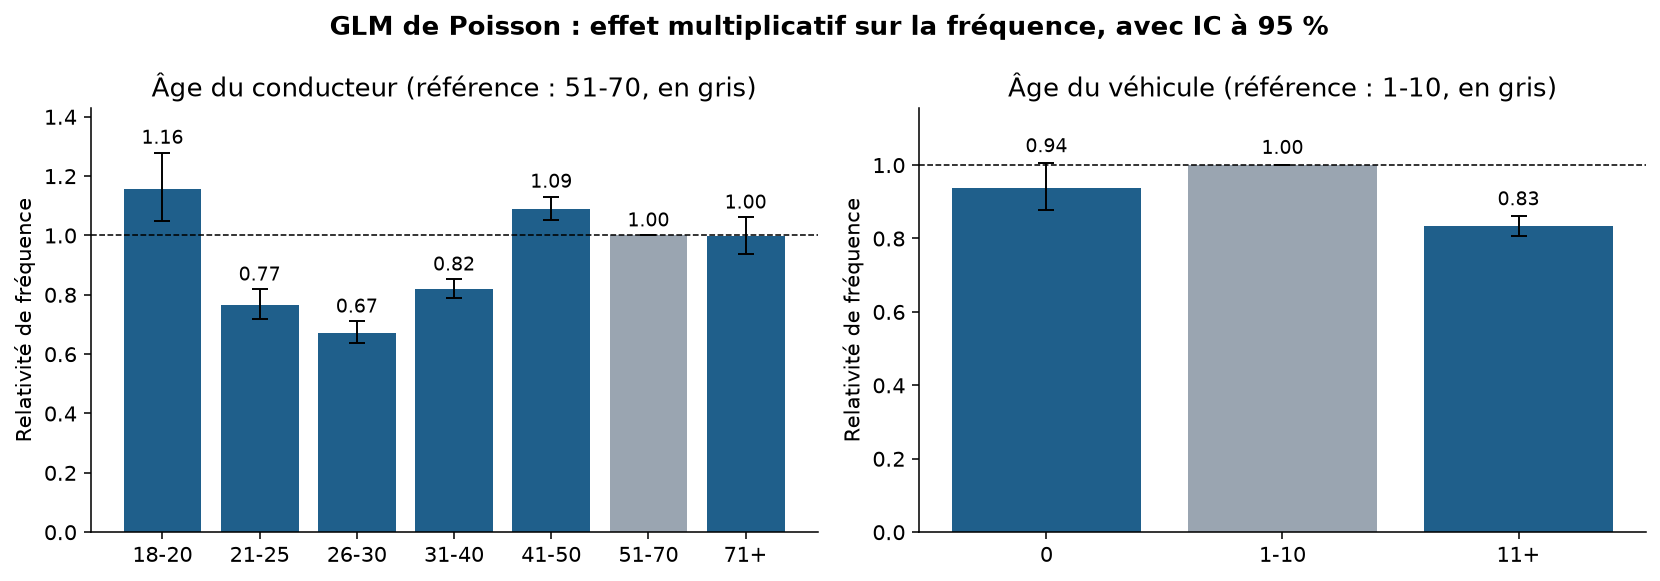

In [7]:
plots.glm_relativities(rel, FIG / "relativites_glm.png")
display(Image(FIG / "relativites_glm.png"))

## 3. XGBoost (Poisson pour la fréquence, Gamma pour le coût)

In [8]:
gbm_f = models.fit_gbm_frequency(train)
gbm_s = models.fit_gbm_severity(train)
print("Arbres retenus (arrêt précoce) : fréquence", gbm_f.best_iteration + 1, "| coût", gbm_s.best_iteration + 1)

Arbres retenus (arrêt précoce) : fréquence 440 | coût 35


## 4. Comparaison sur le jeu de test

Prime pure = fréquence × coût moyen, avec un coefficient d'équilibre calculé sur le train (la charge prédite doit égaler la charge observée).

In [9]:
predictors = {
    "GLM": lambda d: (models.predict_glm_frequency(glm_f, d), models.predict_glm_severity(glm_s, d)),
    "GLM + interactions": lambda d: (models.predict_glm_frequency(glm_fi, d), models.predict_glm_severity(glm_s, d)),
    "XGBoost": lambda d: (models.predict_gbm_frequency(gbm_f, d), models.predict_gbm_severity(gbm_s, d)),
}
y_pp = (test["ClaimAmount"] / test["Exposure"]).to_numpy()
expo = test["Exposure"].to_numpy()
null_f = np.full(len(test), train["ClaimNb"].sum() / train["Exposure"].sum())
null_s = np.full(len(test), train["ClaimAmount"].sum() / train["ClaimNb"].sum())

rows, pp = {"Modèle constant": {
    "Déviance Poisson (fréquence)": evaluation.poisson_deviance(test, null_f),
    "Déviance Gamma (coût moyen)": evaluation.gamma_deviance(test, null_s)}}, {}
for name, predict in predictors.items():
    f_tr, s_tr = predict(train)
    balance = train["ClaimAmount"].sum() / (f_tr * s_tr * train["Exposure"]).sum()
    f, s = predict(test)
    pp[name] = f * s * balance
    rows[name] = {
        "Déviance Poisson (fréquence)": evaluation.poisson_deviance(test, f),
        "Déviance Gamma (coût moyen)": evaluation.gamma_deviance(test, s),
        "Gini prime pure": evaluation.gini(y_pp, pp[name], expo),
        "Charge prédite / observée": (pp[name] * expo).sum() / test["ClaimAmount"].sum(),
    }
pd.DataFrame(rows).T

,Déviance Poisson (fréquence),Déviance Gamma (coût moyen),Gini prime pure,Charge prédite / observée
Modèle constant,0.4789,1.4235,NaN,NaN
GLM,0.4590,1.4376,0.3193,0.9935
GLM + interactions,0.4570,1.4376,0.3311,0.9935
XGBoost,0.4484,1.4196,0.3678,0.9917


Intervalles de confiance à 95 % du Gini et des écarts entre modèles (bootstrap apparié, 200 tirages).

In [10]:
boot = evaluation.bootstrap_gini(y_pp, pp, expo, n_boot=200)
pd.DataFrame({k: {"valeur": v.get("gini", v.get("ecart")), "IC 95 % bas": v["ic95"][0], "IC 95 % haut": v["ic95"][1]}
              for k, v in boot.items()}).T

,valeur,IC 95 % bas,IC 95 % haut
GLM,0.3193,0.2709,0.3680
GLM + interactions,0.3311,0.2867,0.3783
XGBoost,0.3678,0.3249,0.4126
GLM + interactions - GLM,0.0118,0.0062,0.0176
XGBoost - GLM,0.0480,0.0224,0.0776
XGBoost - GLM + interactions,0.0362,0.0095,0.0617


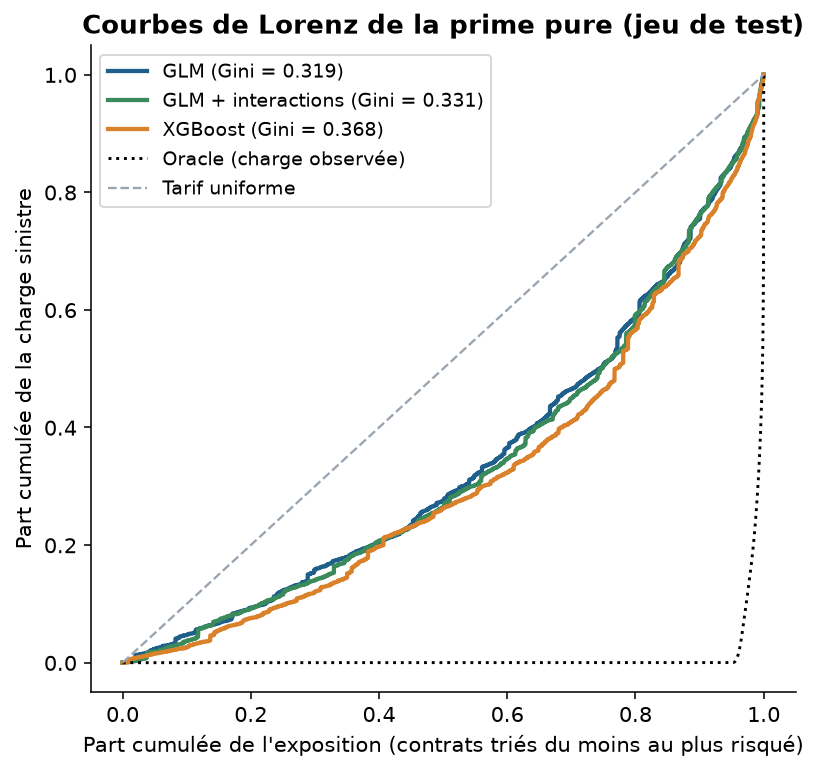

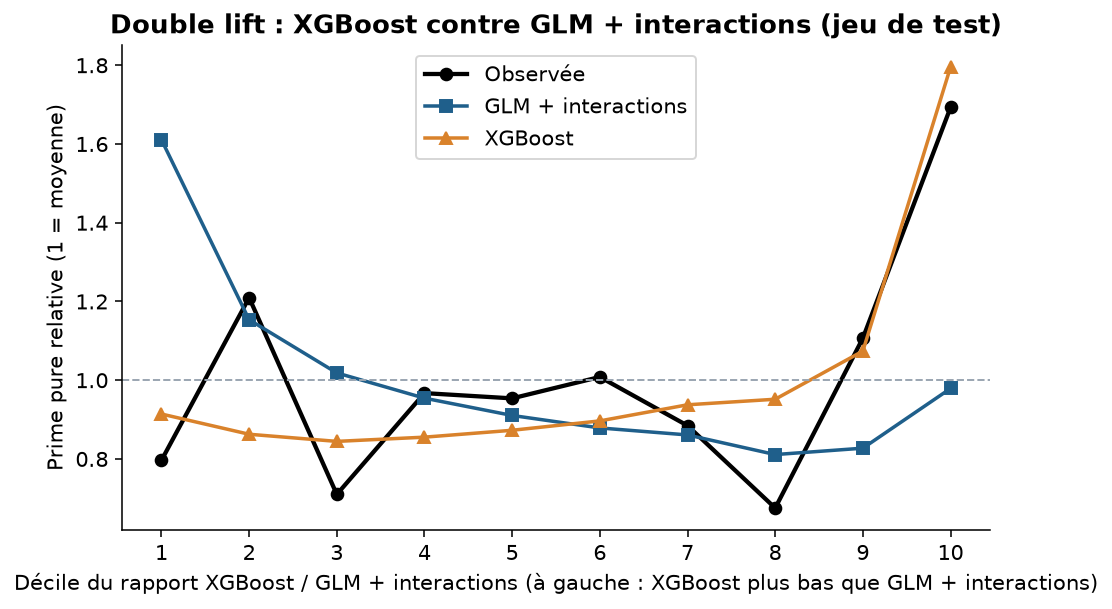

In [11]:
plots.lorenz(test, pp, FIG / "lorenz_prime_pure.png", {k: evaluation.gini(y_pp, v, expo) for k, v in pp.items()})
plots.double_lift(evaluation.double_lift(test, pp["GLM + interactions"], pp["XGBoost"]),
                  "GLM + interactions", "XGBoost", FIG / "double_lift.png")
display(Image(FIG / "lorenz_prime_pure.png"))
display(Image(FIG / "double_lift.png"))

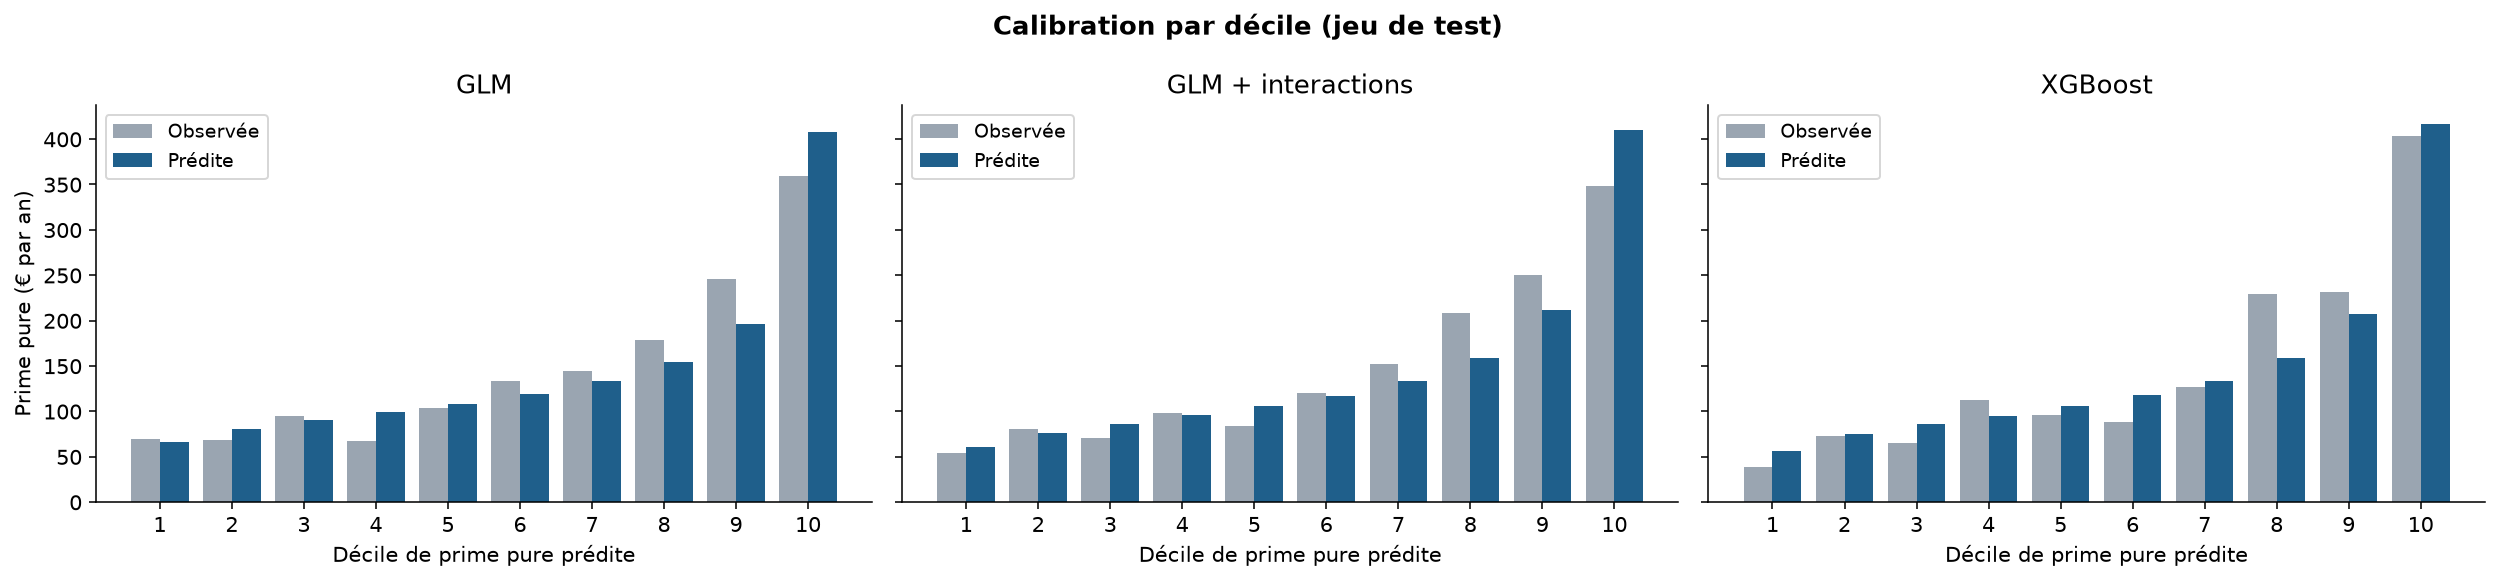

In [12]:
cals = {name: evaluation.calibration_by_decile(test, p) for name, p in pp.items()}
plots.calibration(cals, FIG / "calibration_deciles.png")
display(Image(FIG / "calibration_deciles.png"))

## 5. Interprétation de XGBoost (valeurs SHAP)

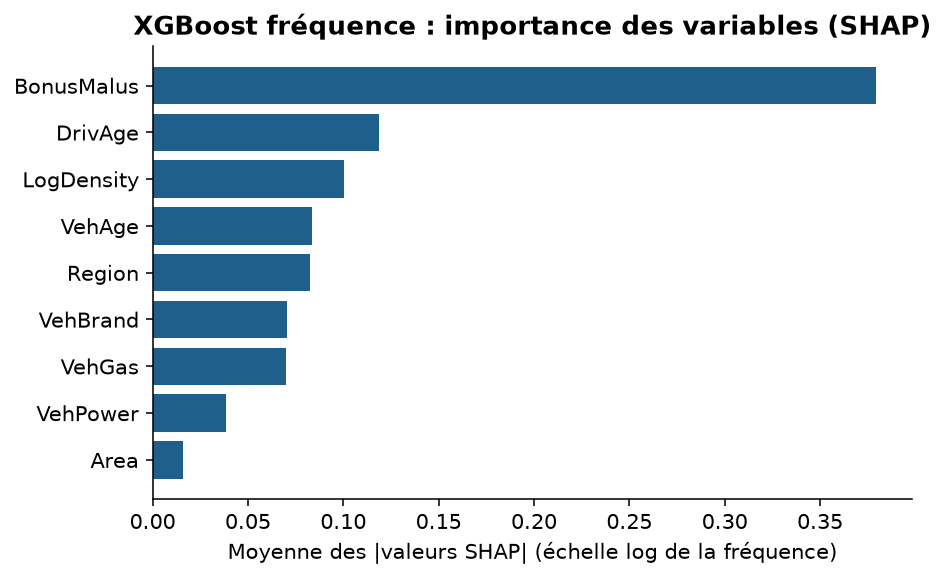

In [13]:
shap = models.shap_values(gbm_f, test.sample(20_000, random_state=2026))
plots.shap_importance(shap, FIG / "shap_frequence.png")
display(Image(FIG / "shap_frequence.png"))

## 6. Sinistres graves

Les modèles sont entraînés sur des montants écrêtés à 200 000 €. La part au-delà est mutualisée par une surcharge proportionnelle.

In [14]:
surcharge = train["ClaimAmountRaw"].sum() / train["ClaimAmount"].sum()
couverture = (pp["XGBoost"] * surcharge * expo).sum() / test["ClaimAmountRaw"].sum()
print(f"Surcharge sinistres graves : +{(surcharge - 1) * 100:.1f} %")
print(f"Charge brute du test couverte par le tarif XGBoost surchargé : {couverture * 100:.1f} %")

Surcharge sinistres graves : +15.4 %
Charge brute du test couverte par le tarif XGBoost surchargé : 102.0 %


## Conclusion

- La fréquence porte l'essentiel du signal ; XGBoost la modélise mieux que le GLM, même enrichi d'interactions.
- Le coût moyen est presque imprévisible avec ces variables.
- Le GLM reste la référence pour une grille tarifaire lisible ; XGBoost classe mieux les risques et peut guider l'ajout d'interactions dans le GLM.